# H4 — 差距是信息还是校准（B6r 重校准实验）

B6r = B6 经两参数 temperature-and-bias logit 映射（train-only 拟合）。若把市场重校准后模型-市场差距几乎不变，说明差距是**信息**而非可修复的校准缺陷。

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
%matplotlib inline


In [2]:
from src.eval.bootstrap import block_deltas, cluster_bootstrap
from src.eval.decisions import h4_verdict

def load(arm):
    return pd.read_csv(ROOT / 'results' / 'preds' / f'preds_{arm}.csv', dtype={'match_id': str})
b4, b6, b6r = load('B4'), load('B6'), load('B6r')
d6 = block_deltas(b4, b6); d6r = block_deltas(b4, b6r)
g6 = cluster_bootstrap(d6, B=10_000, alpha=0.10, seed=20261110)
g6r = cluster_bootstrap(d6r, B=10_000, alpha=0.10, seed=20261110)
print('gap vs B6  = %.4f  (90%% %.4f–%.4f)' % (g6['point'], g6['lo'], g6['hi']))
print('gap vs B6r = %.4f  (90%% %.4f–%.4f)' % (g6r['point'], g6r['lo'], g6r['hi']))

gap vs B6  = 0.0353  (90% 0.0309–0.0401)
gap vs B6r = 0.0354  (90% 0.0309–0.0401)


In [3]:
rng = np.random.default_rng(20261110)
G = d6.n_blocks; idx = rng.integers(0, G, size=(10_000, G))
v6, w6 = d6.values, d6.weights.astype(float)
v6r, w6r = d6r.values, d6r.weights.astype(float)
gg6 = (v6[idx]*w6[idx]).sum(1)/w6[idx].sum(1)
gg6r = (v6r[idx]*w6r[idx]).sum(1)/w6r[idx].sum(1)
rel = (gg6r - gg6)/gg6
lo, hi = np.quantile(rel, [0.05, 0.95])
print('rel change = %.4f  (90%% %.4f–%.4f)' % (rel.mean(), lo, hi))
v = h4_verdict(rel.mean(), lo, hi, g6['point'])
print('H4:', v['decision'], '—', v['reason'])

rel change = 0.0017  (90% -0.0077–0.0114)
H4: 支持 — 相对变化 90% 区间上界 0.011 < 0.25


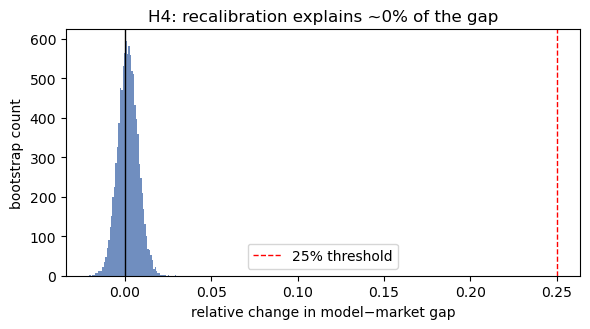

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6,3.4))
ax.hist(rel, bins=60, color='#4c72b0', alpha=.8)
ax.axvline(0, color='k', lw=1); ax.axvline(0.25, color='r', ls='--', lw=1, label='25% threshold')
ax.set_xlabel('relative change in model−market gap'); ax.set_ylabel('bootstrap count')
ax.legend(); ax.set_title('H4: recalibration explains ~0% of the gap')
fig.tight_layout(); plt.show()

**结论**：重校准前后 gap 几乎不变（相对变化 0.0017，90% CI 上界 0.011 < 0.25）⇒ 差距是**信息**而非校准，H4 **支持**。